# 04. 0단계 남은 점검

`plan.md` [0단계] 의 남은 점검 5개. 01 출력(`multiclass/`)과 `patterns.parquet` 만 읽는다.

| 절 | 점검 | 어디에 쓰나 |
|---|---|---|
| 1 | 엣지 1~2개짜리 작은 시도 | 구조로 구분 불가능한 엣지의 정확한 양 → 하한 표 |
| 2 | 분할 끝까지 안 닫힌 CYCLE | 닫히기 전 CYCLE = 경로 = RANDOM 모양 → 하한 표의 CYCLE→RANDOM 칸 |
| 3 | new 시도가 학습 계좌를 공유하나 | 테스트 new 묶음이 얼마나 깨끗한가 |
| 4 | UNMATCHED 가 속한 연결 요소 크기 | UNMATCHED 가 혼자인지, 작게 묶이는지, 거대 덩어리에 붙는지 |
| 5 | 요일·시간대별 클래스 분포 | "UNMATCHED 에 주간 주기" 추정 확인 → 요일·시간대 피처를 넣을지 |

## 0. 설정

In [1]:
import sys
from pathlib import Path
import pandas as pd
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 220)

sys.path.append(str(Path.cwd()))
import mc_lib as M

DATASET = "HI-Large"
TRAIN = ("2022-08-08", "2022-10-02")
VAL   = ("2022-10-03", "2022-10-16")
TEST  = ("2022-10-17", "2022-10-30")
CUTOFF = TEST[1]

windows = M.make_windows(TRAIN, VAL, TEST)
OUT = M.results_dir(DATASET, "04_remaining_checks")
lau = M.load_laundering(DATASET)
att = M.load_attempts(DATASET)
daily = M.load_daily(DATASET)
print(f"세탁 엣지 {len(lau):,}  시도 {len(att):,}")

세탁 엣지 225,546  시도 16,467


## 1. 엣지 1~2개짜리 작은 시도

- `attempts` : 패턴별 시도 중 전체 엣지 수가 1개 / 2개 / 2개 이하인 비율(%)
- `edges` : 분할 × 패턴 엣지 중
  - `full_le_%` = 시도 전체가 엣지 2개 이하 (끝까지 가도 구조가 없음)
  - `visible_le_%` = 분할 끝까지 보이는 시도 엣지가 2개 이하 (그 시점 그래프에서 구조가 없음)
  - `visible_1_%` = 분할 끝까지 보이는 엣지가 자기 자신뿐

In [2]:
sm = M.small_attempts(lau, att, windows)
sm["attempts"]

,attempts,edges1_%,edges2_%,le2_%
pattern_type,,,,
FAN-OUT,2040,20.39,11.52,31.91
FAN-IN,2014,20.11,13.46,33.57
GATHER-SCATTER,2054,0.39,19.81,20.20
SCATTER-GATHER,2067,0.10,20.17,20.27
CYCLE,2086,0.10,28.52,28.62
RANDOM,2001,30.23,10.64,40.88
BIPARTITE,2109,32.24,7.59,39.83
STACK,2096,0.19,34.26,34.45


In [3]:
sm["edges"]

n  full_le_%  visible_le_%  visible_1_%
split pattern_type                                               
train FAN-OUT          6045       8.02         11.18         5.87
      FAN-IN           6465       7.49         10.55         5.34
      GATHER-SCATTER   9012       5.30          8.12         1.35
      SCATTER-GATHER  12537       3.40          4.90         1.09
      CYCLE            6025      10.85         15.60         3.29
      RANDOM           4948      11.74         15.12         8.99
      BIPARTITE        6437       8.84         10.44         6.28
      STACK           11420       5.88          6.67         1.01
val   FAN-OUT          1980       7.02         18.64         8.43
      FAN-IN           1897       8.28         16.92         8.22
      GATHER-SCATTER   3845       3.20          8.43         2.42
      SCATTER-GATHER   3909       3.58          6.75         2.87
      CYCLE            1765       9.80         23.57         8.10
      RANDOM           1425      10.39         22.32        11.72
      BIPARTITE        1730       7.28         12.20         7.28
      STACK            3549       6.31          8.51         2.85
test  FAN-OUT          2131       5.21         14.31         6.52
      FAN-IN           1922       7.86         17.17         7.49
      GATHER-SCATTER   3785       2.72          7.48         2.56
      SCATTER-GATHER   3891       2.90          7.63         2.96
      CYCLE            1853       9.28         20.18         6.64
      RANDOM           1335      11.46         23.07        12.66
      BIPARTITE        1833       7.58         12.60         8.18
      STACK            3437       6.23          8.67         3.35

## 2. CYCLE 닫힘

- `shape` : 가정 확인. CYCLE 의 `edges_eq_accounts_%`(단순 사이클), RANDOM 의 `edges_eq_accounts-1_%`(경로)가 100 에 가까우면 "시도 엣지가 전부 보이면 닫힘" 판단이 맞다
- `closed` : 분할별 CYCLE 엣지 중 분할 끝까지 사이클이 닫힌 비율. `open_%` = 그래프에서 RANDOM(경로)과 같은 모양인 CYCLE 엣지

In [4]:
cy = M.cycle_closure(lau, att, windows)
cy["shape"]

,attempts,edges_eq_accounts_%,edges_eq_accounts-1_%
pattern_type,,,
CYCLE,2086,99.86,0.1
RANDOM,2001,0.00,100.0


In [5]:
cy["closed"]

,n,closed_%,open_%
split,,,
train,6025,70.59,29.41
val,1765,34.33,65.67
test,1853,33.14,66.86


## 3. new 시도의 학습 계좌 공유

- `attempts` : val·test 에서 새로 시작한 시도 중 학습 구간 세탁 거래의 계좌를 하나라도 포함하는 비율 (`share_train_acct_%`), 학습 **패턴** 거래 계좌를 포함하는 비율 (`share_train_pattern_acct_%`)
- `edges` : new 패턴 엣지 / UNMATCHED 엣지 중 양끝 하나가 학습 구간 세탁 계좌인 비율
- 높으면 new 묶음도 계좌를 통해 학습과 이어져 있다 → 계좌 단위 기억으로 맞힐 여지

In [6]:
ns = M.new_attempt_sharing(lau, att, windows)
ns["attempts"]

new_attempts  share_train_acct_%  share_train_pattern_acct_%
split pattern_type                                                                
val   FAN-OUT                  326               61.66                       54.29
      FAN-IN                   288               65.28                       60.07
      GATHER-SCATTER           303               66.34                       64.03
      SCATTER-GATHER           304               76.64                       69.08
      CYCLE                    310               68.06                       62.26
      RANDOM                   306               65.03                       58.17
      BIPARTITE                288               78.82                       72.92
      STACK                    303               85.15                       79.21
test  FAN-OUT                  291               70.10                       63.57
      FAN-IN                   285               69.12                       63.16
      GATHER-SCATTER           277               67.87                       63.18
      SCATTER-GATHER           297               73.06                       69.02
      CYCLE                    277               62.45                       54.15
      RANDOM                   278               65.11                       62.95
      BIPARTITE                325               82.77                       78.77
      STACK                    324               79.63                       72.84

In [7]:
ns["edges"]

n  touch_train_acct_%
split group       pattern_type                             
val   new_pattern BIPARTITE         918               45.75
                  CYCLE             620               55.65
                  FAN-IN            575               43.13
                  FAN-OUT           670               44.63
                  GATHER-SCATTER    740               53.51
                  RANDOM            578               47.58
                  SCATTER-GATHER   1109               48.33
                  STACK            1245               40.16
      unmatched   UNMATCHED       13695               54.74
test  new_pattern BIPARTITE        1033               47.53
                  CYCLE             572               45.80
                  FAN-IN            599               50.58
                  FAN-OUT           647               49.30
                  GATHER-SCATTER    653               53.14
                  RANDOM            502               53.19
                  SCATTER-GATHER    934               54.82
                  STACK            1271               44.06
      unmatched   UNMATCHED       14273               53.18

## 4. UNMATCHED 가 속한 연결 요소 크기 (테스트 끝 기준, 방향 무시)

- 행 = 요소 크기(엣지 수), 열 = 요소 종류 (UNMATCHED 만 / 시도 1개 + UNMATCHED / 여러 시도), 값 = UNMATCHED 엣지 수 · 비율

In [8]:
cc = M.components(lau, CUTOFF)
us = M.unmatched_component_sizes(cc["edges"])
us["counts"]

,unmatched_only,single_attempt+unm,multi_attempt,total
comp_edges,,,,
1,26799,0,0,26799
2,12146,658,0,12804
3,4311,943,27,5281
4-5,2073,841,267,3181
6-10,292,489,366,1147
11-50,0,239,1024,1263
51-1000,1301,0,109,1410
1000+,0,0,29276,29276
ALL,46922,3170,31069,81161


In [9]:
us["share"]

,unmatched_only,single_attempt+unm,multi_attempt,total
comp_edges,,,,
1,33.02,0.00,0.00,33.02
2,14.97,0.81,0.00,15.78
3,5.31,1.16,0.03,6.51
4-5,2.55,1.04,0.33,3.92
6-10,0.36,0.60,0.45,1.41
11-50,0.00,0.29,1.26,1.56
51-1000,1.60,0.00,0.13,1.74
1000+,0.00,0.00,36.07,36.07
ALL,57.81,3.91,38.28,100.00


## 5. 요일 · 시간대별 클래스 분포 (학습~테스트 구간)

- `weekday` : 클래스 × 요일 비율(%), 행 합 100. 맨 아래 `NORMAL(all tx)` = 같은 기간 정상 거래 전체
- `weekday_ratio` : 균등(14.29%) 대비 배수. 1 에서 멀수록 요일 신호가 있다
- `hour` : 클래스 × 시간대 비율(%)

In [10]:
wh = M.weekday_hour(lau, windows, daily)
wh["weekday"]

,Mon,Tue,Wed,Thu,Fri,Sat,Sun
pattern_type,,,,,,,
FAN-OUT,14.18,14.30,13.93,14.71,14.30,14.56,14.02
FAN-IN,13.45,14.68,14.91,13.94,14.03,14.72,14.26
GATHER-SCATTER,13.62,13.37,14.05,14.31,14.60,15.18,14.87
SCATTER-GATHER,13.83,13.92,14.38,14.32,14.30,14.13,15.12
CYCLE,14.12,14.28,13.85,14.70,14.27,14.34,14.42
RANDOM,13.70,13.31,14.53,14.26,14.72,14.14,15.33
BIPARTITE,14.10,13.78,13.95,13.85,14.43,14.57,15.32
STACK,13.95,13.89,13.88,14.22,14.48,14.89,14.70
UNMATCHED,14.60,14.79,14.86,14.84,16.50,12.22,12.19


In [11]:
wh["weekday_ratio"]

,Mon,Tue,Wed,Thu,Fri,Sat,Sun
pattern_type,,,,,,,
FAN-OUT,0.99,1.00,0.98,1.03,1.00,1.02,0.98
FAN-IN,0.94,1.03,1.04,0.98,0.98,1.03,1.00
GATHER-SCATTER,0.95,0.94,0.98,1.00,1.02,1.06,1.04
SCATTER-GATHER,0.97,0.97,1.01,1.00,1.00,0.99,1.06
CYCLE,0.99,1.00,0.97,1.03,1.00,1.00,1.01
RANDOM,0.96,0.93,1.02,1.00,1.03,0.99,1.07
BIPARTITE,0.99,0.96,0.98,0.97,1.01,1.02,1.07
STACK,0.98,0.97,0.97,1.00,1.01,1.04,1.03
UNMATCHED,1.02,1.04,1.04,1.04,1.16,0.86,0.85


In [12]:
wh["hour"]

hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
pattern_type,,,,,,,,,,,,,,,,,,,,,,,,
FAN-OUT,2.38,2.33,2.34,2.33,2.66,3.35,3.34,3.47,4.71,5.16,4.94,7.29,7.33,6.62,6.37,6.69,6.64,4.90,5.06,4.92,1.77,1.88,1.84,1.68
FAN-IN,2.62,2.32,2.44,2.09,2.30,3.43,3.34,3.23,4.78,4.65,5.08,7.52,7.11,7.15,6.67,6.71,6.76,5.01,5.14,4.72,1.64,1.79,1.87,1.64
GATHER-SCATTER,2.45,2.43,2.23,2.59,2.24,3.46,3.27,3.27,4.68,4.84,4.88,6.96,7.08,6.98,7.02,6.56,6.75,4.84,5.21,4.70,1.93,1.86,1.93,1.83
SCATTER-GATHER,2.25,2.21,2.05,2.06,2.22,3.66,3.54,3.32,4.94,4.68,5.28,7.51,7.42,6.83,6.88,7.15,7.11,5.05,4.91,4.97,1.51,1.53,1.44,1.48
CYCLE,2.42,2.50,2.39,2.43,2.24,3.26,3.42,3.61,4.98,4.68,4.95,7.38,7.05,7.18,6.63,6.94,6.48,4.83,4.89,4.80,1.89,1.64,1.72,1.71
RANDOM,2.37,2.31,2.41,2.57,2.52,3.63,3.32,3.55,4.79,5.19,4.77,6.99,7.46,7.19,6.94,6.21,6.21,4.87,4.35,4.61,2.31,1.80,1.87,1.75
BIPARTITE,1.96,1.91,1.84,2.08,1.90,3.44,3.29,3.43,4.73,4.97,5.31,8.04,7.76,7.26,6.81,7.88,7.20,5.15,4.96,5.04,1.16,1.28,1.32,1.28
STACK,1.81,1.91,1.79,2.02,1.90,3.48,3.34,3.43,4.99,5.19,5.12,8.16,8.10,7.42,6.94,6.94,7.10,4.78,5.37,5.11,1.17,1.28,1.31,1.35
UNMATCHED,4.25,4.15,4.17,4.11,4.12,4.18,4.31,4.24,4.09,4.17,4.12,4.10,4.23,4.12,4.09,4.23,4.13,4.27,4.15,4.05,4.22,4.06,4.20,4.22


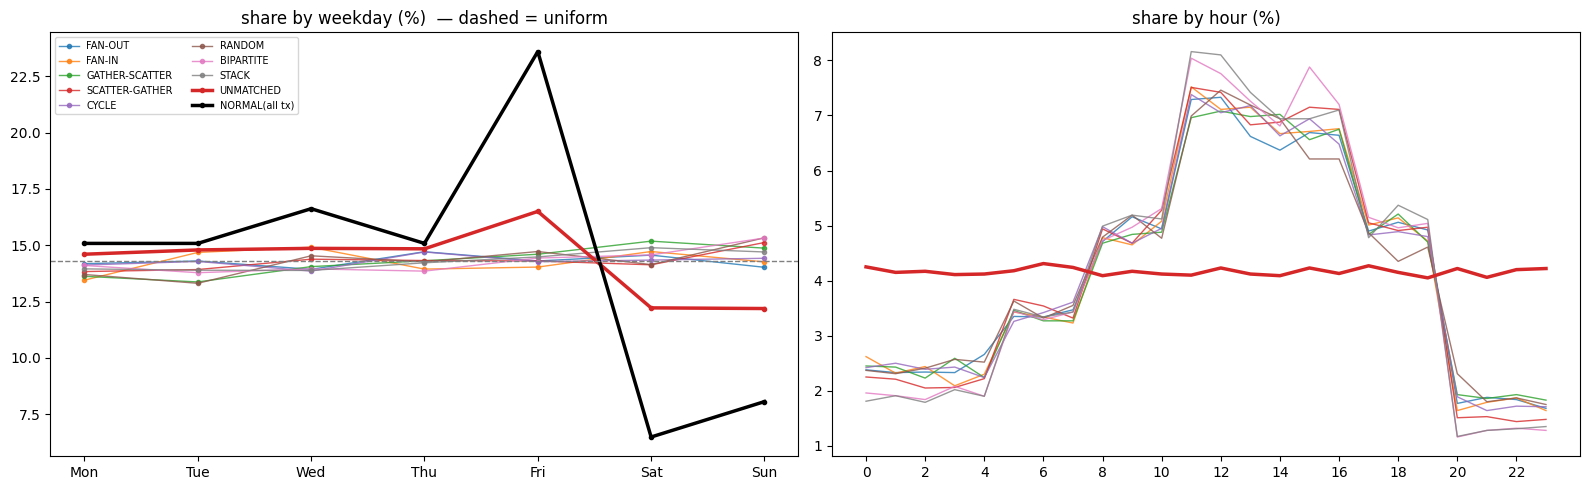

In [13]:
fig = M.plot_weekday_hour(wh, path=OUT / "weekday_hour.png")

## 6. 저장

In [14]:
for name, df in {"small_attempts": sm["attempts"], "small_edges": sm["edges"],
                 "cycle_shape": cy["shape"], "cycle_closed": cy["closed"],
                 "new_sharing_attempts": ns["attempts"], "new_sharing_edges": ns["edges"],
                 "unmatched_comp_counts": us["counts"], "unmatched_comp_share": us["share"],
                 "weekday": wh["weekday"], "weekday_ratio": wh["weekday_ratio"], "hour": wh["hour"]}.items():
    df.to_csv(OUT / f"{name}.csv", encoding="utf-8-sig")
sorted(p.name for p in OUT.iterdir())

['cycle_closed.csv',
 'cycle_shape.csv',
 'hour.csv',
 'new_sharing_attempts.csv',
 'new_sharing_edges.csv',
 'small_attempts.csv',
 'small_edges.csv',
 'unmatched_comp_counts.csv',
 'unmatched_comp_share.csv',
 'weekday.csv',
 'weekday_hour.png',
 'weekday_ratio.csv']